# Comparison between broadcast and tactical

This notebook takes you the comparison in the gaps in broadcast and tactical view

---

In [5]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from kloppy import metrica
from games import asset_paths

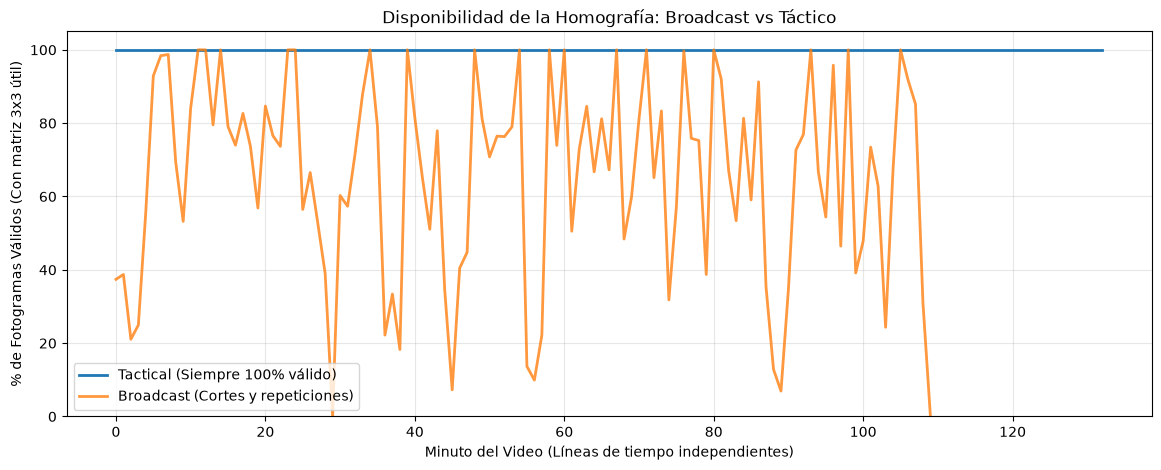

In [6]:
# 1. Agregar el directorio raíz al path para que Python encuentre 'games.py'
sys.path.insert(0, os.path.abspath('..'))

# 2. Obtener las rutas exactas de los archivos CSV de homografía
path_tac = asset_paths(source='tactical')['homography']
path_bro = asset_paths(source='broadcast')['homography']

# 3. Cargar solo la columna 'valid' para optimizar la memoria
df_tac = pd.read_csv(path_tac, usecols=['valid'])
df_bro = pd.read_csv(path_bro, usecols=['valid'])

# 4. Configurar la agrupación por minuto (25 fps * 60 segundos = 1500 frames)
fps = 25
frames_per_minute = fps * 60

# 5. Calcular el promedio de validez por minuto (multiplicado por 100 para porcentaje)
tac_valid_pm = df_tac['valid'].groupby(df_tac.index // frames_per_minute).mean() * 100
bro_valid_pm = df_bro['valid'].groupby(df_bro.index // frames_per_minute).mean() * 100

# 6. Graficar los resultados
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(tac_valid_pm.index, tac_valid_pm, label='Tactical (Siempre 100% válido)', color='#1f77b4', lw=2)
ax.plot(bro_valid_pm.index, bro_valid_pm, label='Broadcast (Cortes y repeticiones)', color='#ff7f0e', alpha=0.8, lw=2)

ax.set_xlabel('Minuto del Video (Líneas de tiempo independientes)')
ax.set_ylabel('% de Fotogramas Válidos (Con matriz 3x3 útil)')
ax.set_title('Disponibilidad de la Homografía: Broadcast vs Táctico')
ax.set_ylim(0, 105)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Cargando ATD Táctico (esto puede tomar un minuto)...
Cargando ATD Broadcast (esto puede tomar un minuto)...
Balón Táctico presente en 113488 de 199319 frames (56.9%)
Balón Broadcast presente en 83121 de 164488 frames (50.5%)


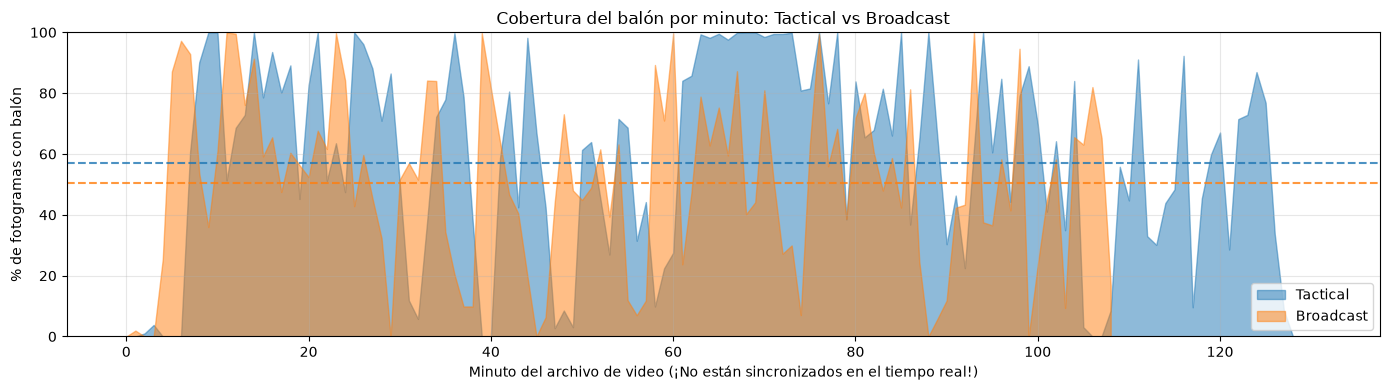

In [7]:

# Agregar la raíz al path para importar games.py
sys.path.insert(0, os.path.abspath('..'))


# 1. Obtener las rutas de ambas fuentes
paths_tac = asset_paths(source='tactical')
paths_bro = asset_paths(source='broadcast')

# 2. Cargar los datos de seguimiento (ATD)
print("Cargando ATD Táctico (esto puede tomar un minuto)...")
# Usa limit=30000 si se te queda sin memoria
dataset_tac = metrica.load_tracking_epts(meta_data=paths_tac['atd_meta'], raw_data=paths_tac['atd_raw'])

print("Cargando ATD Broadcast (esto puede tomar un minuto)...")
dataset_bro = metrica.load_tracking_epts(meta_data=paths_bro['atd_meta'], raw_data=paths_bro['atd_raw'])

# Convertir a DataFrames para facilitar el análisis
df_tac = dataset_tac.to_df()
df_bro = dataset_bro.to_df()

# 3. Detectar dónde el balón es visible (no es NaN en ambas coordenadas)
seen_tac = df_tac[['ball_x', 'ball_y']].notna().all(axis=1).values
seen_bro = df_bro[['ball_x', 'ball_y']].notna().all(axis=1).values

print('Balón Táctico presente en %d de %d frames (%.1f%%)' % (seen_tac.sum(), len(seen_tac), 100 * seen_tac.mean()))
print('Balón Broadcast presente en %d de %d frames (%.1f%%)' % (seen_bro.sum(), len(seen_bro), 100 * seen_bro.mean()))

# 4. Agrupar por minuto (1500 frames a 25 fps)
frames_per_minute = 1500

# Truncar los arrays para que encajen en bloques completos de un minuto
tac_per_minute = seen_tac[:len(seen_tac) // frames_per_minute * frames_per_minute].reshape(-1, frames_per_minute).mean(axis=1)
bro_per_minute = seen_bro[:len(seen_bro) // frames_per_minute * frames_per_minute].reshape(-1, frames_per_minute).mean(axis=1)

# 5. Graficar la comparativa
fig, ax = plt.subplots(figsize=(14, 4))

# Área del Táctico
ax.fill_between(np.arange(len(tac_per_minute)), tac_per_minute * 100, color='#1f77b4', alpha=0.5, label='Tactical')
ax.axhline(100 * seen_tac.mean(), color='#1f77b4', ls='--', alpha=0.8)

# Área del Broadcast
ax.fill_between(np.arange(len(bro_per_minute)), bro_per_minute * 100, color='#ff7f0e', alpha=0.5, label='Broadcast')
ax.axhline(100 * seen_bro.mean(), color='#ff7f0e', ls='--', alpha=0.8)

ax.set_xlabel('Minuto del archivo de video (¡No están sincronizados en el tiempo real!)')
ax.set_ylabel('% de fotogramas con balón')
ax.set_ylim(0, 100)
ax.set_title('Cobertura del balón por minuto: Tactical vs Broadcast')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()